# Assignment 2: training pipeline


# Assignment 2: olive peacock spot detection on olive leaves

This notebook is the full training pipeline. It runs start to finish with
`uv run python main.py train`, with no manual steps, and does the following:

1. **Downloads the dataset** from Roboflow Universe (`project-9k7w7/olive1-ngwty`, v1):
   olive leaves in three classes (healthy, Aculus olearius and peacock spot).
2. **Describes the dataset**: images per class and per split, plus visual examples
   to check whether the test set resembles what the technician would see in the field.
3. **Finetunes `yolo11n-cls`** starting from the pretrained checkpoint.
4. **Evaluates it on the test split** against two baselines (the pretrained model
   without finetuning, and one that always predicts the majority class), with
   per-class results.
5. **Costs each threshold**: a missed peacock spot costs ~€400/ha and an unnecessary
   treatment ~€110/ha, with a 25% base rate.
6. **Saves to `weights/` and `results/`** everything the app needs, so the dashboard
   never has to train anything.

In [1]:
from pathlib import Path
import random

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from roboflow import Roboflow

from api_key import load_api_key


ROOT = Path.cwd()
DATA_DIR = ROOT / "datasets" / "olive1-v1"   
RESULTS_DIR = ROOT / "results"               
WEIGHTS_DIR = ROOT / "weights"               
RESULTS_DIR.mkdir(exist_ok=True)
WEIGHTS_DIR.mkdir(exist_ok=True)


WORKSPACE = "project-9k7w7"
PROJECT = "olive1-ngwty"
VERSION = 1

SEED = 42
random.seed(SEED)

In [2]:
if not (DATA_DIR / "train").exists():
    rf = Roboflow(api_key=load_api_key())
    version = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION)
    version.download("folder", location=str(DATA_DIR))
else:
    print("Dataset ya descargado en", DATA_DIR)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /Users/joseluishervasdecela_1/Desktop/daiist-assignment-2/datasets/olive1-v1 in folder:: 100%|██████████| 8727/8727 [00:00<00:00, 8945.71it/s]


In [3]:
valid_dir = DATA_DIR / "valid"
if valid_dir.exists() and not (DATA_DIR / "val").exists():
    valid_dir.rename(DATA_DIR / "val")

print(sorted(p.name for p in DATA_DIR.iterdir()))

['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'val']


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
SPLITS = ["train", "val", "test"]

def list_images(folder):
    return [f for f in folder.iterdir() if f.suffix.lower() in IMG_EXT]

def original_id(file):
    # Roboflow names files like "524_jpg.rf.<hash>.jpg". Augmented copies of the
    # same photo share the part before ".rf.", so that part identifies the original.
    return file.name.split(".rf.")[0]

rows = []
for split in SPLITS:
    for class_dir in sorted(p for p in (DATA_DIR / split).iterdir() if p.is_dir()):
        files = list_images(class_dir)
        rows.append({
            "split": split,
            "class": class_dir.name,
            "files": len(files),                                # includes augmented copies
            "originals": len({original_id(f) for f in files}),  # real, distinct photos
        })

counts = pd.DataFrame(rows)
counts.to_csv(RESULTS_DIR / "dataset_counts.csv", index=False)

print("Files on disk (train includes augmented copies):")
print(counts.pivot(index="class", columns="split", values="files")[SPLITS].to_string())
print("\nDistinct original photos:")
print(counts.pivot(index="class", columns="split", values="originals")[SPLITS].to_string())

Files on disk (train includes augmented copies):
split               train  val  test
class                               
Healthy              2268   49    86
aculus_olearius      2238   42    88
olive_peacock_spot   3726   67   149

Distinct original photos:
split               train  val  test
class                               
Healthy               756   49    86
aculus_olearius       746   42    88
olive_peacock_spot   1242   67   149


In [5]:
# Leakage check: the same original photo should never appear in two splits.
# If it did, the model would be tested on photos it already saw in training.
def ids_in_split(split):
    return {f"{f.parent.name}/{original_id(f)}"
            for f in (DATA_DIR / split).rglob("*") if f.suffix.lower() in IMG_EXT}

ids = {s: ids_in_split(s) for s in SPLITS}
print("train & val :", len(ids["train"] & ids["val"]))
print("train & test:", len(ids["train"] & ids["test"]))
print("val & test  :", len(ids["val"] & ids["test"]))

# Image size after Roboflow preprocessing (expected 224x224, stretched)
sample = list_images(DATA_DIR / "test" / counts["class"].iloc[0])[0]
print("\nImage size:", Image.open(sample).size)

train & val : 0
train & test: 0
val & test  : 0

Image size: (224, 224)


Healthy: ['A319_jpg', 'A442_jpg', 'A593_jpg', 'A697_JPG']
aculus_olearius: ['103_jpg', '133_jpg', '136_jpg', '154_jpg']
olive_peacock_spot: ['A140_jpg', 'A271_jpg', 'A302_jpg', 'A344_jpg']


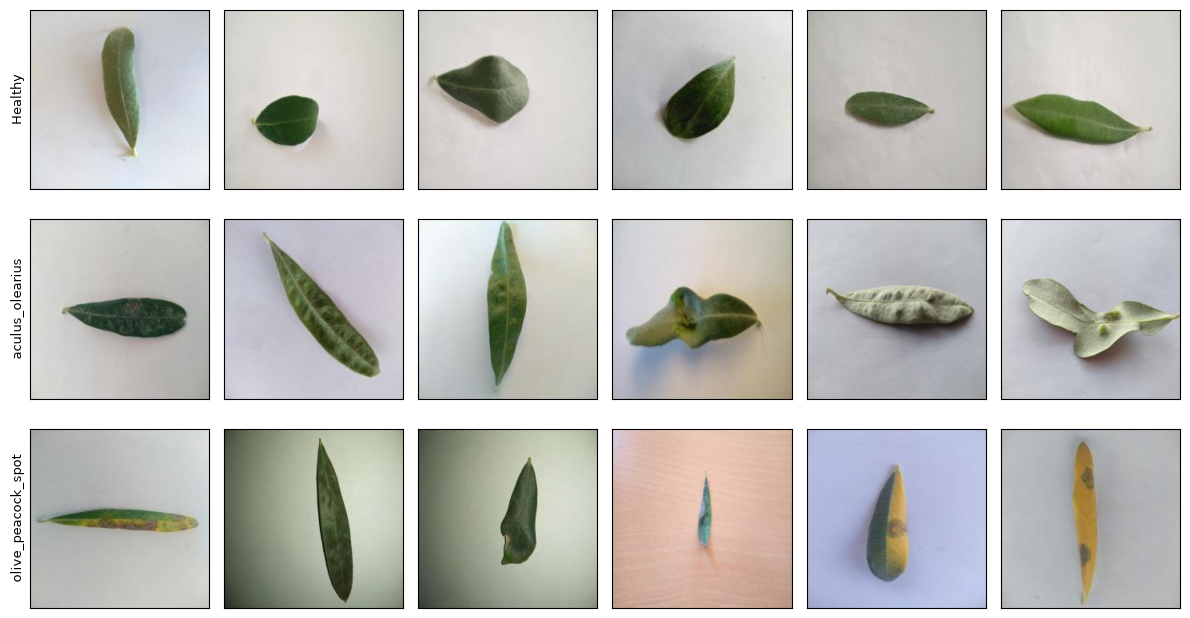

In [6]:
# Show 6 random test images per class and the first filenames of each class.
# Purpose: check whether classes differ in background or source (camera, naming),
# which the model could learn instead of the disease.
classes = sorted(p.name for p in (DATA_DIR / "test").iterdir() if p.is_dir())
n_cols = 6
fig, axes = plt.subplots(len(classes), n_cols, figsize=(2 * n_cols, 2.2 * len(classes)))
for r, cls in enumerate(classes):
    files = sorted(list_images(DATA_DIR / "test" / cls))
    for c, f in enumerate(random.sample(files, n_cols)):
        ax = axes[r, c]
        ax.imshow(Image.open(f))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(cls, fontsize=9)
    print(f"{cls}: {[original_id(f) for f in files[:4]]}")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "test_samples.png", dpi=120)

## Finetuning yolo11n-cls

I start from the `yolo11n-cls` checkpoint pretrained on ImageNet and finetune it on
the three olive classes. Training uses the `val` split to pick the best epoch and
stops early if validation accuracy stops improving. The best checkpoint is copied
to `weights/`, which is what the app loads.

Set the environment variable `SKIP_TRAINING=1` to reuse the committed weights
instead of retraining (used for running the evaluation cells locally).

In [8]:
import os
import json
import shutil

import torch
from ultralytics import YOLO

# Training settings (recorded in results/ and in REPORT.md)
BASE_MODEL = "yolo11n-cls.pt"   # pretrained on ImageNet
EPOCHS = 30
IMGSZ = 224                     # matches Roboflow's 224x224 preprocessing
BATCH = 64
PATIENCE = 10                   # stop if val accuracy doesn't improve for 10 epochs
DEVICE = 0 if torch.cuda.is_available() else "cpu"   # GPU on Colab, CPU elsewhere

BEST_WEIGHTS = WEIGHTS_DIR / "olive_cls_best.pt"
SKIP_TRAINING = os.environ.get("SKIP_TRAINING") == "1"

if SKIP_TRAINING and BEST_WEIGHTS.exists():
    print("SKIP_TRAINING=1: using existing weights at", BEST_WEIGHTS)
else:
    model = YOLO(BASE_MODEL)
    model.train(
        data=str(DATA_DIR),       # folder with train/ val/ test/, one subfolder per class
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        patience=PATIENCE,
        seed=SEED,
        deterministic=True,
        device=DEVICE,
        project=str(ROOT / "runs"),
        name="olive_cls",
        exist_ok=True,
    )
    # Ultralytics saves best.pt (best val accuracy) and last.pt (final epoch).
    # We keep best.pt: the last epoch may already be overfitting.
    best = Path(model.trainer.save_dir) / "weights" / "best.pt"
    shutil.copy(best, BEST_WEIGHTS)
    print("Best weights copied to", BEST_WEIGHTS)

    # Record exactly how this model was trained
    config = {"base_model": BASE_MODEL, "epochs": EPOCHS, "imgsz": IMGSZ,
              "batch": BATCH, "patience": PATIENCE, "seed": SEED,
              "device": str(DEVICE), "gpu": torch.cuda.get_device_name(0)
              if torch.cuda.is_available() else None}
    (RESULTS_DIR / "train_config.json").write_text(json.dumps(config, indent=2))
    # Ultralytics may download helper models (e.g. for its AMP check) into weights/.
    # check.py loads every .pt in weights/, so keep only our finetuned model there.
    for extra in WEIGHTS_DIR.glob("*.pt"):
        if extra != BEST_WEIGHTS:
            extra.unlink()
            print("Removed stray file from weights/:", extra.name)

SKIP_TRAINING=1: using existing weights at /Users/joseluishervasdecela_1/Desktop/daiist-assignment-2/weights/olive_cls_best.pt


## Evaluation on the test split

All numbers below are on the 323 test images, which were never used for training
or for choosing the best epoch. The positive class is `olive_peacock_spot`, since it
is the only one that triggers a copper treatment. Here the predicted class is
simply the most probable one; thresholds and costs come later.

In [9]:
import numpy as np

model = YOLO(str(BEST_WEIGHTS))
CLASS_NAMES = [model.names[i] for i in range(len(model.names))]  # order of the model's outputs
POSITIVE = "olive_peacock_spot"
PROB_COLS = [f"p_{c}" for c in CLASS_NAMES]

# Score every test image and keep the full probability vector, not only the label:
# the cost analysis and the dashboard need probabilities to move the threshold.
rows = []
for true_cls in CLASS_NAMES:
    files = [str(f) for f in sorted(list_images(DATA_DIR / "test" / true_cls))]
    for res in model.predict(files, imgsz=IMGSZ, device=DEVICE, verbose=False, stream=True):
        probs = res.probs.data.cpu().numpy()
        row = {"file": Path(res.path).name, "true": true_cls}
        row.update({col: float(p) for col, p in zip(PROB_COLS, probs)})
        rows.append(row)

preds = pd.DataFrame(rows)
preds["pred"] = [CLASS_NAMES[i] for i in preds[PROB_COLS].to_numpy().argmax(axis=1)]
preds.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

print(len(preds), "test images scored")
print(preds.head().to_string())

323 test images scored
                                                file     true  p_Healthy  p_aculus_olearius  p_olive_peacock_spot     pred
0   A319_jpg.rf.8c237145142c3840e4c28b4be0825938.jpg  Healthy   0.778209       1.018444e-02              0.211607  Healthy
1   A442_jpg.rf.e1c26371fbbb0e539b2d21c0c850f1bb.jpg  Healthy   0.606175       5.205423e-02              0.341770  Healthy
2   A593_jpg.rf.a09f79b3d5b969a4f9404b87615a5472.jpg  Healthy   0.578686       3.359482e-01              0.085366  Healthy
3   A697_JPG.rf.75074d037ad4b323e1d3c666b27e2aa6.jpg  Healthy   0.993862       5.465782e-03              0.000673  Healthy
4  B-102_JPG.rf.77d6441bc0e6f8641b04f994a82143d5.jpg  Healthy   0.999994       6.736275e-07              0.000005  Healthy


In [10]:
def confusion_matrix(true, pred, labels):
    # Rows = true class, columns = predicted class
    idx = {c: i for i, c in enumerate(labels)}
    cm = np.zeros((len(labels), len(labels)), dtype=int)
    for t, p in zip(true, pred):
        cm[idx[t], idx[p]] += 1
    return pd.DataFrame(cm, index=[f"true {c}" for c in labels],
                        columns=[f"pred {c}" for c in labels])

def per_class_report(true, pred, labels):
    cm = confusion_matrix(true, pred, labels).to_numpy().astype(float)
    tp = np.diag(cm)
    predicted = cm.sum(axis=0)   # how many times each class was predicted
    actual = cm.sum(axis=1)      # how many images truly belong to each class
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = tp / actual
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(tp), where=(precision + recall) > 0)
    return pd.DataFrame({"precision": precision, "recall": recall, "f1": f1,
                         "support": actual.astype(int)}, index=labels).round(3)

cm_ft = confusion_matrix(preds["true"], preds["pred"], CLASS_NAMES)
report_ft = per_class_report(preds["true"], preds["pred"], CLASS_NAMES)
acc_ft = (preds["true"] == preds["pred"]).mean()

cm_ft.to_csv(RESULTS_DIR / "confusion_finetuned.csv")
report_ft.to_csv(RESULTS_DIR / "per_class_finetuned.csv")

print(f"Test accuracy: {acc_ft:.3f}\n")
print(report_ft.to_string(), "\n")
print(cm_ft.to_string())

Test accuracy: 0.975

                    precision  recall     f1  support
Healthy                 0.955   0.988  0.971       86
aculus_olearius         0.966   0.966  0.966       88
olive_peacock_spot      0.993   0.973  0.983      149 

                         pred Healthy  pred aculus_olearius  pred olive_peacock_spot
true Healthy                       85                     1                        0
true aculus_olearius                2                    85                        1
true olive_peacock_spot             2                     2                      145


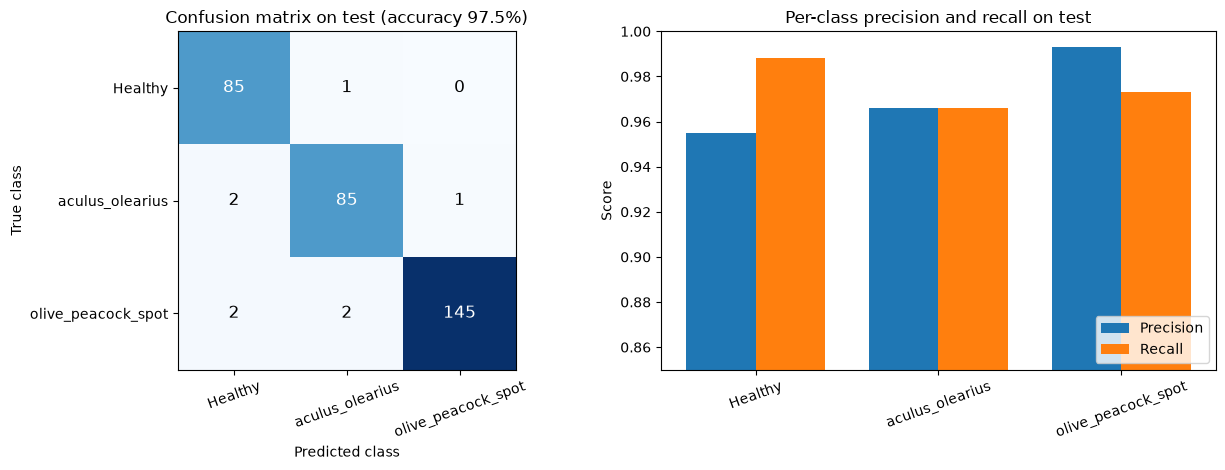

In [11]:
# Plots saved to results/ for REPORT.md and the dashboard (no plt.show(), see cell 7)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1) Confusion matrix as a heatmap, with the count written in each cell
ax = axes[0]
cm_values = cm_ft.to_numpy()
ax.imshow(cm_values, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=20)
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"Confusion matrix on test (accuracy {acc_ft:.1%})")
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        color = "white" if cm_values[i, j] > cm_values.max() / 2 else "black"
        ax.text(j, i, cm_values[i, j], ha="center", va="center", color=color, fontsize=12)

# 2) Precision and recall per class, side by side
ax = axes[1]
x = np.arange(len(CLASS_NAMES))
width = 0.38
ax.bar(x - width / 2, report_ft["precision"], width, label="Precision")
ax.bar(x + width / 2, report_ft["recall"], width, label="Recall")
ax.set_xticks(x, CLASS_NAMES, rotation=20)
ax.set_ylim(0.85, 1.0)   # zoomed in: all values are above 0.95
ax.set_ylabel("Score")
ax.set_title("Per-class precision and recall on test")
ax.legend(loc="lower right")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "eval_finetuned.png", dpi=130)

## Baselines

1. **Majority class.** Always predicts the most frequent class in *train*
   (`olive_peacock_spot`). In business terms: treat every parcel.
2. **Pretrained yolo11n-cls, zero-shot.** The ImageNet checkpoint without any
   finetuning. Its 1,000 ImageNet labels never match ours, so used literally it
   would score 0%. To give it a fair chance, I map each ImageNet label to the olive
   class it most often corresponds to on the *validation* split (never test), and
   map labels unseen in validation to the majority class. The network itself is
   not trained.

In [12]:
# Majority class is taken from TRAIN counts, not test, so the baseline doesn't peek
train_counts = counts[counts["split"] == "train"].set_index("class")["originals"]
MAJORITY = train_counts.idxmax()
print("Majority class in train:", MAJORITY)

pred_majority = [MAJORITY] * len(preds)
report_maj = per_class_report(preds["true"], pred_majority, CLASS_NAMES)
acc_maj = (preds["true"] == MAJORITY).mean()
print(f"Majority baseline accuracy: {acc_maj:.3f}\n")
print(report_maj.to_string())

Majority class in train: olive_peacock_spot
Majority baseline accuracy: 0.461

                    precision  recall     f1  support
Healthy                 0.000     0.0  0.000       86
aculus_olearius         0.000     0.0  0.000       88
olive_peacock_spot      0.461     1.0  0.631      149


In [13]:
# The ImageNet checkpoint, no finetuning (downloads to the repo root, gitignored)
zs_model = YOLO(BASE_MODEL)

def imagenet_top1(split):
    # For each image: its true olive class and the ImageNet label the model gives it
    out = []
    for true_cls in CLASS_NAMES:
        files = [str(f) for f in sorted(list_images(DATA_DIR / split / true_cls))]
        for res in zs_model.predict(files, imgsz=IMGSZ, device=DEVICE, verbose=False, stream=True):
            out.append({"true": true_cls, "imagenet": zs_model.names[res.probs.top1]})
    return pd.DataFrame(out)

zs_val = imagenet_top1("val")
zs_test = imagenet_top1("test")

# What the pretrained model "sees" in each class (top 3 ImageNet labels on test)
print("Most frequent ImageNet labels per true class (test):")
for cls, labels in zs_test.groupby("true")["imagenet"]:
    print(f"  {cls}: {labels.value_counts().head(3).to_dict()}")

# Translation table learned on VALIDATION: ImageNet label -> most common olive class
mapping = zs_val.groupby("imagenet")["true"].agg(lambda s: s.value_counts().idxmax())
zs_test["pred"] = zs_test["imagenet"].map(mapping).fillna(MAJORITY)

report_zs = per_class_report(zs_test["true"], zs_test["pred"], CLASS_NAMES)
acc_zs = (zs_test["true"] == zs_test["pred"]).mean()
print(f"\nZero-shot baseline accuracy: {acc_zs:.3f}  "
      f"({zs_test['imagenet'].isin(mapping.index).mean():.0%} of test labels seen in val)\n")
print(report_zs.to_string())

Most frequent ImageNet labels per true class (test):
  Healthy: {'cucumber': 26, 'lacewing': 25, 'quill': 11}
  aculus_olearius: {'cucumber': 23, 'lacewing': 20, 'quill': 16}
  olive_peacock_spot: {'cucumber': 32, 'quill': 29, 'lacewing': 21}

Zero-shot baseline accuracy: 0.409  (90% of test labels seen in val)

                    precision  recall     f1  support
Healthy                 0.387   0.535  0.449       86
aculus_olearius         0.279   0.216  0.244       88
olive_peacock_spot      0.493   0.450  0.470      149


                                    accuracy  peacock_spot_recall  peacock_spot_precision
finetuned yolo11n-cls                  0.975                0.973                   0.993
pretrained zero-shot (val mapping)     0.409                0.450                   0.493
majority class                         0.461                1.000                   0.461


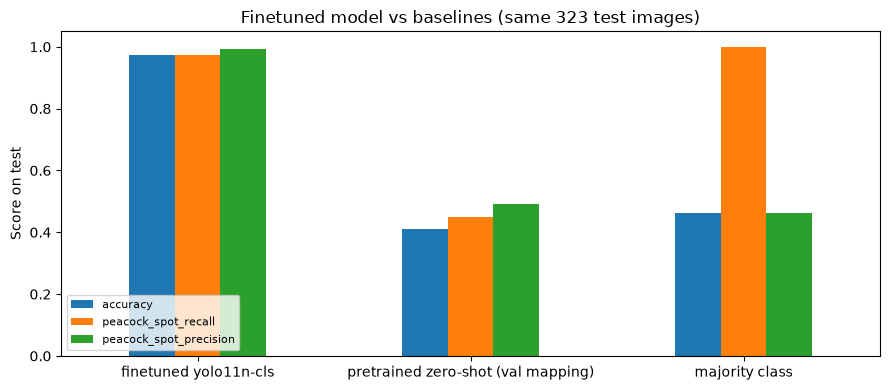

In [14]:
# One table with the three models on the same test split
comparison = pd.DataFrame({
    "accuracy": [acc_ft, acc_zs, acc_maj],
    "peacock_spot_recall": [report_ft.loc[POSITIVE, "recall"], report_zs.loc[POSITIVE, "recall"],
                            report_maj.loc[POSITIVE, "recall"]],
    "peacock_spot_precision": [report_ft.loc[POSITIVE, "precision"], report_zs.loc[POSITIVE, "precision"],
                               report_maj.loc[POSITIVE, "precision"]],
}, index=["finetuned yolo11n-cls", "pretrained zero-shot (val mapping)", "majority class"]).round(3)
comparison.to_csv(RESULTS_DIR / "baselines_comparison.csv")
print(comparison.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
comparison.plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1.05)    # full scale here: the gaps between models are large
ax.set_ylabel("Score on test")
ax.set_title("Finetuned model vs baselines (same 323 test images)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "baselines_comparison.png", dpi=130)

8 misclassified test images

                                                              file                true                pred  p_olive_peacock_spot
0  IMG_20190806_151505_jpg.rf.a89fecebb81375e1a4fe83ef8487bc22.jpg             Healthy     aculus_olearius                 0.004
1                  136_jpg.rf.0677926e5247e884b5fa076a41164294.jpg     aculus_olearius             Healthy                 0.001
2                  278_jpg.rf.d949315f2081effeb9c6a333cbb20942.jpg     aculus_olearius  olive_peacock_spot                 0.852
3                   86_jpg.rf.c1fe8081b81e8b40707c1bbf6f7db53e.jpg     aculus_olearius             Healthy                 0.020
4                 A458_jpg.rf.eb4b27826967ae1106c4208334484bf4.jpg  olive_peacock_spot     aculus_olearius                 0.431
5             DSC_1671_JPG.rf.62168d826de1a359fac0f79502d4a242.jpg  olive_peacock_spot     aculus_olearius                 0.032
6  IMG_20190729_202018_jpg.rf.afca9c0a49c84e53d6383da33fabd379.jpg  

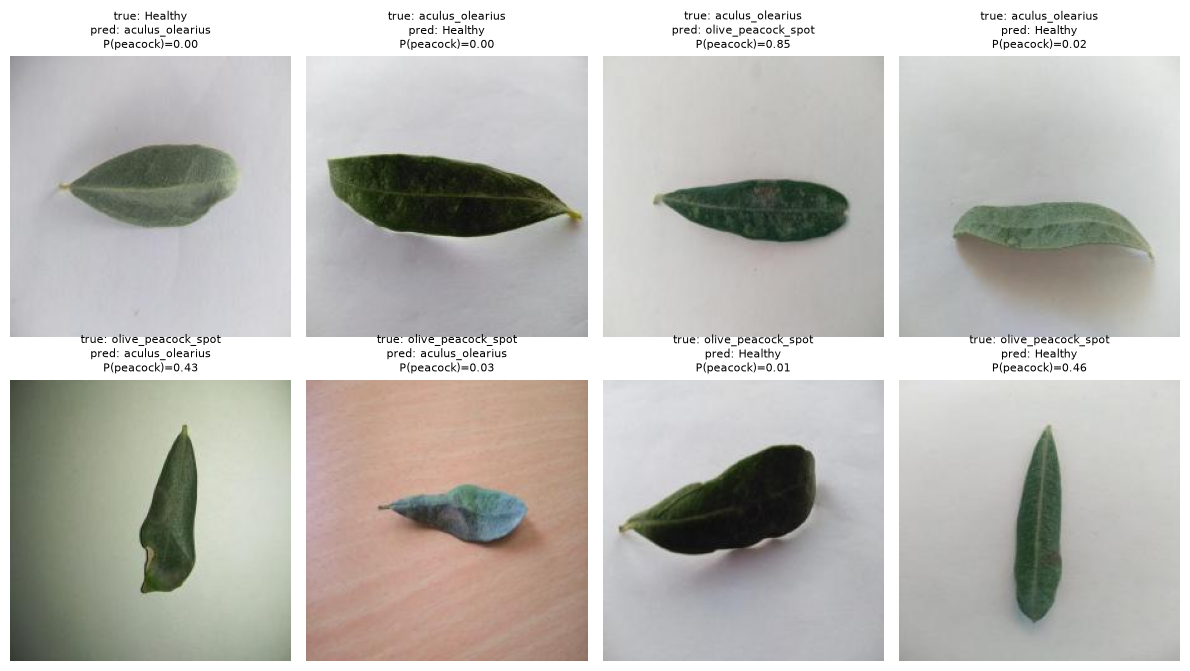

In [15]:
# Show every misclassified test image with its true class, prediction and P(peacock spot).
# Purpose: name the failure modes (tiny lesions? yellowing? background?) instead of
# hiding them behind the 97.5% average.
errors = preds[preds["true"] != preds["pred"]].reset_index(drop=True)
print(len(errors), "misclassified test images\n")
print(errors[["file", "true", "pred", f"p_{POSITIVE}"]].round(3).to_string())

n_cols = 4
n_rows = int(np.ceil(len(errors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3.4 * n_rows))
for ax in np.array(axes).ravel():
    ax.axis("off")
for ax, (_, row) in zip(np.array(axes).ravel(), errors.iterrows()):
    ax.imshow(Image.open(DATA_DIR / "test" / row["true"] / row["file"]))
    ax.set_title(f"true: {row['true']}\npred: {row['pred']}\n"
                 f"P(peacock)={row[f'p_{POSITIVE}']:.2f}", fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "test_errors.png", dpi=130)

## Cost matrix and threshold sweep

Costs per hectare (see the business section): TP €110 (the treatment), FP €110
(a wasted treatment), FN €400 (lost harvest), TN €0. The score is P(peacock spot);
a parcel is treated when the score is at or above the threshold.

The test set is 46% peacock spot, but I assume 25% in production. I therefore use
the test set only for the true positive rate and false positive rate at each
threshold, and compute the expected cost per 1,000 parcels at the 25% base rate.
I sweep thresholds from 0 to 1 instead of trusting the 0.275 break-even, because the
model was trained on 45% positives and its probabilities are not calibrated for 25%.

In [16]:
# Cost matrix, € per hectare (one case = one parcel of ~1 ha)
C_TP, C_FP, C_FN, C_TN = 110.0, 110.0, 400.0, 0.0
BASE_RATE = 0.25
N_CASES = 1000

scores = preds[f"p_{POSITIVE}"].to_numpy()
is_pos = (preds["true"] == POSITIVE).to_numpy()

def expected_cost(tpr, fpr, base_rate=BASE_RATE, c_tp=C_TP, c_fp=C_FP,
                  c_fn=C_FN, c_tn=C_TN, n=N_CASES):
    # Reweight to the production base rate: use rates from test, not test counts
    pos_part = base_rate * (tpr * c_tp + (1 - tpr) * c_fn)
    neg_part = (1 - base_rate) * (fpr * c_fp + (1 - fpr) * c_tn)
    return n * (pos_part + neg_part)

def sweep(scores, is_pos, thresholds, **cost_kwargs):
    rows = []
    for t in thresholds:
        treat = scores >= t
        tp = int((treat & is_pos).sum());  fn = int((~treat & is_pos).sum())
        fp = int((treat & ~is_pos).sum()); tn = int((~treat & ~is_pos).sum())
        tpr, fpr = tp / (tp + fn), fp / (fp + tn)
        rows.append({"threshold": t, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                     "tpr": tpr, "fpr": fpr,
                     "cost_per_1000": expected_cost(tpr, fpr, **cost_kwargs)})
    return pd.DataFrame(rows)

def pick_threshold(sw):
    # With few test errors the curve is a staircase and several thresholds tie.
    # Take the middle of the tied ones, so the choice isn't on the edge of a step.
    best = sw["cost_per_1000"].min()
    tied = sw.loc[np.isclose(sw["cost_per_1000"], best), "threshold"]
    return float(tied.iloc[len(tied) // 2]), float(best), float(tied.min()), float(tied.max())

THRESHOLDS = np.round(np.arange(0.0, 1.0001, 0.01), 2)
cost_sweep = sweep(scores, is_pos, THRESHOLDS)
best_t, best_cost, tie_lo, tie_hi = pick_threshold(cost_sweep)

# Reference policies, priced the same way
argmax_treat = (preds["pred"] == POSITIVE).to_numpy()
reference = {
    "do nothing (never treat)": expected_cost(0.0, 0.0),
    "treat every parcel": expected_cost(1.0, 1.0),
    "model, most probable class": expected_cost(argmax_treat[is_pos].mean(),
                                                argmax_treat[~is_pos].mean()),
    f"model, threshold {best_t:.2f}": best_cost,
    "perfect classifier": expected_cost(1.0, 0.0),
}

cost_sweep.to_csv(RESULTS_DIR / "cost_sweep.csv", index=False)
operating_point = {"costs": {"TP": C_TP, "FP": C_FP, "FN": C_FN, "TN": C_TN},
                   "base_rate": BASE_RATE, "threshold": best_t,
                   "cost_per_1000": best_cost, "tied_range": [tie_lo, tie_hi],
                   "reference_cost_per_1000": reference}
(RESULTS_DIR / "operating_point.json").write_text(json.dumps(operating_point, indent=2))

print(f"Best threshold: {best_t:.2f} (same minimum cost from {tie_lo:.2f} to {tie_hi:.2f})\n")
print(cost_sweep.loc[cost_sweep["threshold"] == best_t].to_string(index=False), "\n")
for name, cost in reference.items():
    print(f"{name:32s} €{cost:>10,.0f} per 1,000 parcels")

Best threshold: 0.39 (same minimum cost from 0.35 to 0.43)

 threshold  TP  FN  FP  TN      tpr      fpr  cost_per_1000
      0.39 147   2   1 173 0.986577 0.005747   28947.292293 

do nothing (never treat)         €   100,000 per 1,000 parcels
treat every parcel               €   110,000 per 1,000 parcels
model, most probable class       €    29,920 per 1,000 parcels
model, threshold 0.39            €    28,947 per 1,000 parcels
perfect classifier               €    27,500 per 1,000 parcels


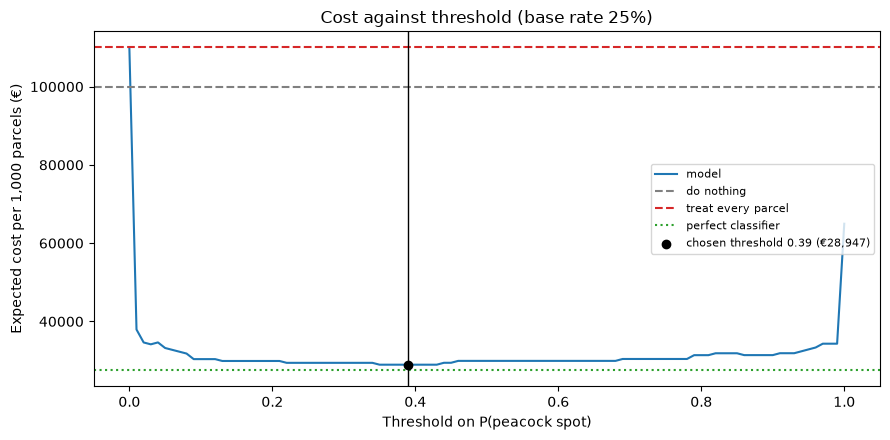

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cost_sweep["threshold"], cost_sweep["cost_per_1000"], label="model")
ax.axhline(reference["do nothing (never treat)"], ls="--", color="grey", label="do nothing")
ax.axhline(reference["treat every parcel"], ls="--", color="tab:red", label="treat every parcel")
ax.axhline(reference["perfect classifier"], ls=":", color="tab:green", label="perfect classifier")
ax.axvline(best_t, color="black", lw=1)
ax.scatter([best_t], [best_cost], color="black", zorder=5,
           label=f"chosen threshold {best_t:.2f} (€{best_cost:,.0f})")
ax.set_xlabel("Threshold on P(peacock spot)")
ax.set_ylabel("Expected cost per 1,000 parcels (€)")
ax.set_title(f"Cost against threshold (base rate {BASE_RATE:.0%})")
ax.legend(fontsize=8, loc="center right")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "cost_vs_threshold.png", dpi=130)

In [18]:
# Sensitivity: how the best threshold and cost move if the base rate or the cost
# of a missed peacock spot (olive oil price) are wrong
rows = []
for base_rate in [0.05, 0.10, 0.25, 0.40, 0.60]:
    for c_fn in [200.0, 400.0, 800.0]:
        sw = sweep(scores, is_pos, THRESHOLDS, base_rate=base_rate, c_fn=c_fn)
        t, cost, lo, hi = pick_threshold(sw)
        rows.append({
            "base_rate": base_rate, "cost_FN": c_fn,
            "best_threshold": t, "tied_range": f"{lo:.2f}-{hi:.2f}",
            "model_cost": round(cost),
            "do_nothing": round(expected_cost(0, 0, base_rate=base_rate, c_fn=c_fn)),
            "treat_all": round(expected_cost(1, 1, base_rate=base_rate, c_fn=c_fn)),
        })
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(RESULTS_DIR / "cost_sensitivity.csv", index=False)
print(sensitivity.to_string(index=False))

 base_rate  cost_FN  best_threshold tied_range  model_cost  do_nothing  treat_all
      0.05    200.0            0.88  0.86-0.90        5742       10000     110000
      0.05    400.0            0.88  0.86-0.90        6279       20000     110000
      0.05    800.0            0.39  0.35-0.43        6564       40000     110000
      0.10    200.0            0.88  0.86-0.90       11483       20000     110000
      0.10    400.0            0.39  0.35-0.43       11958       40000     110000
      0.10    800.0            0.39  0.35-0.43       12495       80000     110000
      0.25    200.0            0.39  0.35-0.43       28276       50000     110000
      0.25    400.0            0.39  0.35-0.43       28947      100000     110000
      0.25    800.0            0.39  0.35-0.43       30290      200000     110000
      0.40    200.0            0.39  0.35-0.43       44863       80000     110000
      0.40    400.0            0.39  0.35-0.43       45936      160000     110000
      0.40    80

## Human review band

Two thresholds on P(peacock spot): below `t_low` the parcel is not treated, at or
above `t_high` it is treated, and in between the photo goes to the cooperative's
agronomist, who decides correctly. Assumptions: a review takes 3 minutes of an
agronomist at ~€30/h, i.e. €1.50 per case; 4 technicians visit ~100 parcels a day in
season; the agronomist can spend at most 1 hour a day on reviews (20 photos, 20% of
cases). I search all pairs of thresholds for the lowest expected cost that respects
that capacity.

In [ ]:
REVIEW_MINUTES = 3
AGRONOMIST_EUR_PER_HOUR = 30.0
C_REVIEW = AGRONOMIST_EUR_PER_HOUR * REVIEW_MINUTES / 60   # €1.50 per review
CASES_PER_DAY = 100
REVIEW_CAPACITY_MIN_PER_DAY = 60
MAX_REVIEW_SHARE = REVIEW_CAPACITY_MIN_PER_DAY / REVIEW_MINUTES / CASES_PER_DAY  # 0.20

def band_cost(t_low, t_high, base_rate=BASE_RATE, c_review=C_REVIEW, n=N_CASES):
    # Share of positives / negatives that end up in each of the three outcomes
    passed = scores < t_low
    treated = scores >= t_high
    review = ~passed & ~treated
    pos_pass, pos_rev, pos_treat = passed[is_pos].mean(), review[is_pos].mean(), treated[is_pos].mean()
    neg_rev, neg_treat = review[~is_pos].mean(), treated[~is_pos].mean()
    # Reviewed cases get the right decision: positives are treated, negatives are not
    cost = n * (base_rate * (pos_pass * C_FN + pos_treat * C_TP + pos_rev * (C_TP + c_review))
                + (1 - base_rate) * (neg_treat * C_FP + neg_rev * c_review))
    review_share = base_rate * pos_rev + (1 - base_rate) * neg_rev
    fn_share = base_rate * pos_pass          # missed peacock spots per case
    return cost, review_share, fn_share

rows = []
for i, t_low in enumerate(THRESHOLDS):
    for t_high in THRESHOLDS[i:]:
        cost, share, fn = band_cost(t_low, t_high)
        rows.append({"t_low": t_low, "t_high": t_high, "cost_per_1000": cost,
                     "review_share": share, "missed_per_1000": fn * N_CASES})
band = pd.DataFrame(rows)

# Best pair within the agronomist's capacity; among equal costs, review the fewest
feasible = band[band["review_share"] <= MAX_REVIEW_SHARE]
best_band = feasible.sort_values(["cost_per_1000", "review_share"]).iloc[0]
T_LOW, T_HIGH = float(best_band["t_low"]), float(best_band["t_high"])
# Safety margin: the swept t_low (0.01) sits just below the lowest peacock spot score
# in test (0.011), i.e. it is tuned to two test images. Halve it to leave a margin for
# unseen leaves, as long as the review load still fits the agronomist's capacity.
SAFETY_FACTOR = 0.5
T_LOW_SWEPT = T_LOW
T_LOW = round(T_LOW_SWEPT * SAFETY_FACTOR, 3)
cost, share, fn = band_cost(T_LOW, T_HIGH)
assert share <= MAX_REVIEW_SHARE, "safety margin would exceed review capacity"
best_band = pd.Series({"t_low": T_LOW, "t_high": T_HIGH, "cost_per_1000": cost,
                       "review_share": share, "missed_per_1000": fn * N_CASES})
print(f"Swept t_low = {T_LOW_SWEPT:.3f}, used t_low = {T_LOW:.3f} (safety margin)")
reviews_per_day = best_band["review_share"] * CASES_PER_DAY
minutes_per_day = reviews_per_day * REVIEW_MINUTES
print(f"Review band: t_low = {T_LOW:.3f}, t_high = {T_HIGH:.3f}")
print(f"Share sent to review: {best_band['review_share']:.1%} "
      f"-> {reviews_per_day:.1f} photos/day, {minutes_per_day:.0f} min/day of agronomist time")
print(f"Expected cost: €{best_band['cost_per_1000']:,.0f} per 1,000 parcels, "
      f"missed peacock spots: {best_band['missed_per_1000']:.1f} per 1,000")

Swept t_low = 0.010, used t_low = 0.005 (safety margin)
Review band: t_low = 0.01, t_high = 0.86
Share sent to review: 13.4% -> 13.4 photos/day, 40 min/day of agronomist time
Expected cost: €27,701 per 1,000 parcels, missed peacock spots: 0.0 per 1,000


                       policy  cost_per_1000 review_share  photos_per_day  agronomist_min_per_day
                   do nothing         100000         0.0%             0.0                       0
agronomist checks every photo          29000       100.0%           100.0                     300
 model alone (threshold 0.39)          28947         0.0%             0.0                       0
model + review (0.01 to 0.86)          27701        13.4%            13.4                      40 

Moving the lower threshold (upper fixed):
 t_low  t_high  cost_per_1000 review_share  missed_per_1000
 0.005    0.86          27701        13.4%              0.0
 0.010    0.86          27662        10.8%              0.0
 0.020    0.86          28095         7.2%              1.7
 0.050    0.86          28553         5.3%              3.4
 0.100    0.86          28514         2.7%              3.4
 0.200    0.86          28508         2.3%              3.4
 0.390    0.86          28495         1.4%    

211

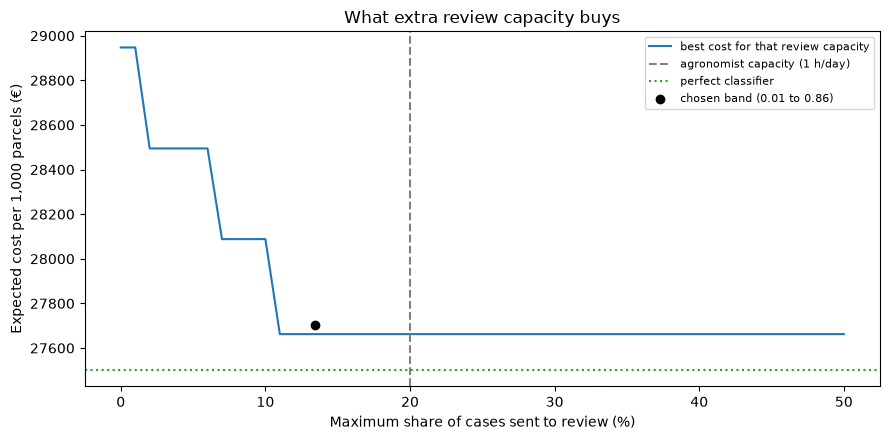

In [ ]:
# 1) The four policies the brief asks for, with the workload each one implies
def workload(review_share):
    photos = review_share * CASES_PER_DAY
    return photos, photos * REVIEW_MINUTES

policies = {
    "do nothing": (expected_cost(0.0, 0.0), 0.0),
    "agronomist checks every photo": (expected_cost(1.0, 0.0) + N_CASES * C_REVIEW, 1.0),
    f"model alone (threshold {best_t:.2f})": (best_cost, 0.0),
    f"model + review ({T_LOW:.3f} to {T_HIGH:.3f})": (best_band["cost_per_1000"], best_band["review_share"]),
}
policy_rows = []
for name, (cost, share) in policies.items():
    photos, minutes = workload(share)
    policy_rows.append({"policy": name, "cost_per_1000": round(cost),
                        "review_share": f"{share:.1%}", "photos_per_day": round(photos, 1),
                        "agronomist_min_per_day": round(minutes)})
policy_table = pd.DataFrame(policy_rows)
policy_table.to_csv(RESULTS_DIR / "policy_comparison.csv", index=False)
print(policy_table.to_string(index=False), "\n")

# 2) Robustness: how much the result depends on the exact lower threshold
robust_rows = []
for t_low in [0.005, 0.01, 0.02, 0.05, 0.10, 0.20, best_t]:
    cost, share, fn = band_cost(t_low, T_HIGH)
    robust_rows.append({"t_low": t_low, "t_high": T_HIGH, "cost_per_1000": round(cost),
                        "review_share": f"{share:.1%}", "missed_per_1000": round(fn * N_CASES, 1)})
print("Moving the lower threshold (upper fixed):")
print(pd.DataFrame(robust_rows).to_string(index=False))

# 3) Best achievable cost for each review capacity
caps = np.round(np.arange(0, 0.51, 0.01), 2)
frontier = [band[band["review_share"] <= c]["cost_per_1000"].min() for c in caps]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(caps * 100, frontier, label="best cost for that review capacity")
ax.axvline(MAX_REVIEW_SHARE * 100, ls="--", color="grey", label="agronomist capacity (1 h/day)")
ax.axhline(reference["perfect classifier"], ls=":", color="tab:green", label="perfect classifier")
ax.scatter([best_band["review_share"] * 100], [best_band["cost_per_1000"]], color="black", zorder=5,
           label=f"chosen band ({T_LOW:.3f} to {T_HIGH:.3f})")
ax.set_xlabel("Maximum share of cases sent to review (%)")
ax.set_ylabel("Expected cost per 1,000 parcels (€)")
ax.set_title("What extra review capacity buys")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "review_capacity.png", dpi=130)

# 4) Save everything the dashboard needs about the review band
review_config = {"t_low": T_LOW, "t_high": T_HIGH, "review_cost": C_REVIEW,
                 "review_minutes": REVIEW_MINUTES, "cases_per_day": CASES_PER_DAY,
                 "max_review_share": MAX_REVIEW_SHARE,
                 "cost_per_1000": float(best_band["cost_per_1000"]),
                 "review_share": float(best_band["review_share"])}
(RESULTS_DIR / "review_band.json").write_text(json.dumps(review_config, indent=2))